# MODULE 46 — FACIAL RECOGNITION

## 46.1 Recognition Pipeline

**Priority:** Must Know  
**Domain:** Deep Learning · Computer Vision

Now we're entering the actual facial recognition stage. 🔥

In Module 45, we studied how to detect a face, identify facial landmarks, align it and prepare it through preprocessing.

Module 46 builds on that foundation:

> How does a computer determine whether two face images belong to the same person?

---

## 1. Understanding the Recognition Pipeline

Your syllabus gives this sequence:

```text
Image
  ↓
Face Detection
  ↓
Face Alignment
  ↓
Face Representation
  ↓
Embedding
  ↓
Similarity
  ↓
Decision
```

Let's understand each stage.

### Stage 1 — Image

The input can come from:

- A smartphone camera.
- CCTV footage.
- An uploaded photograph.
- An access-control camera.

The image contains pixel information, but the computer doesn't inherently understand the person's identity.

### Stage 2 — Face Detection

The detection model locates the face in the image.

It identifies the face using a bounding box.

```text
Original Image
      ↓
Face Detector
      ↓
Face Bounding Box
```

Example:

```python
bbox = (50, 40, 250, 240)
```

**Output:** The location of the face.

Remember:

> Detection answers "Where is the face?", not "Who is this person?"

### Stage 3 — Face Alignment

The detected face is geometrically standardized using facial landmarks.

It helps correct:

- Rotation.
- Scale differences.
- Position differences.

```text
Detected Face
      ↓
Facial Landmarks
      ↓
Geometric Transformation
      ↓
Aligned Face
```

**Output:** A consistently positioned face image.

### Stage 4 — Face Representation

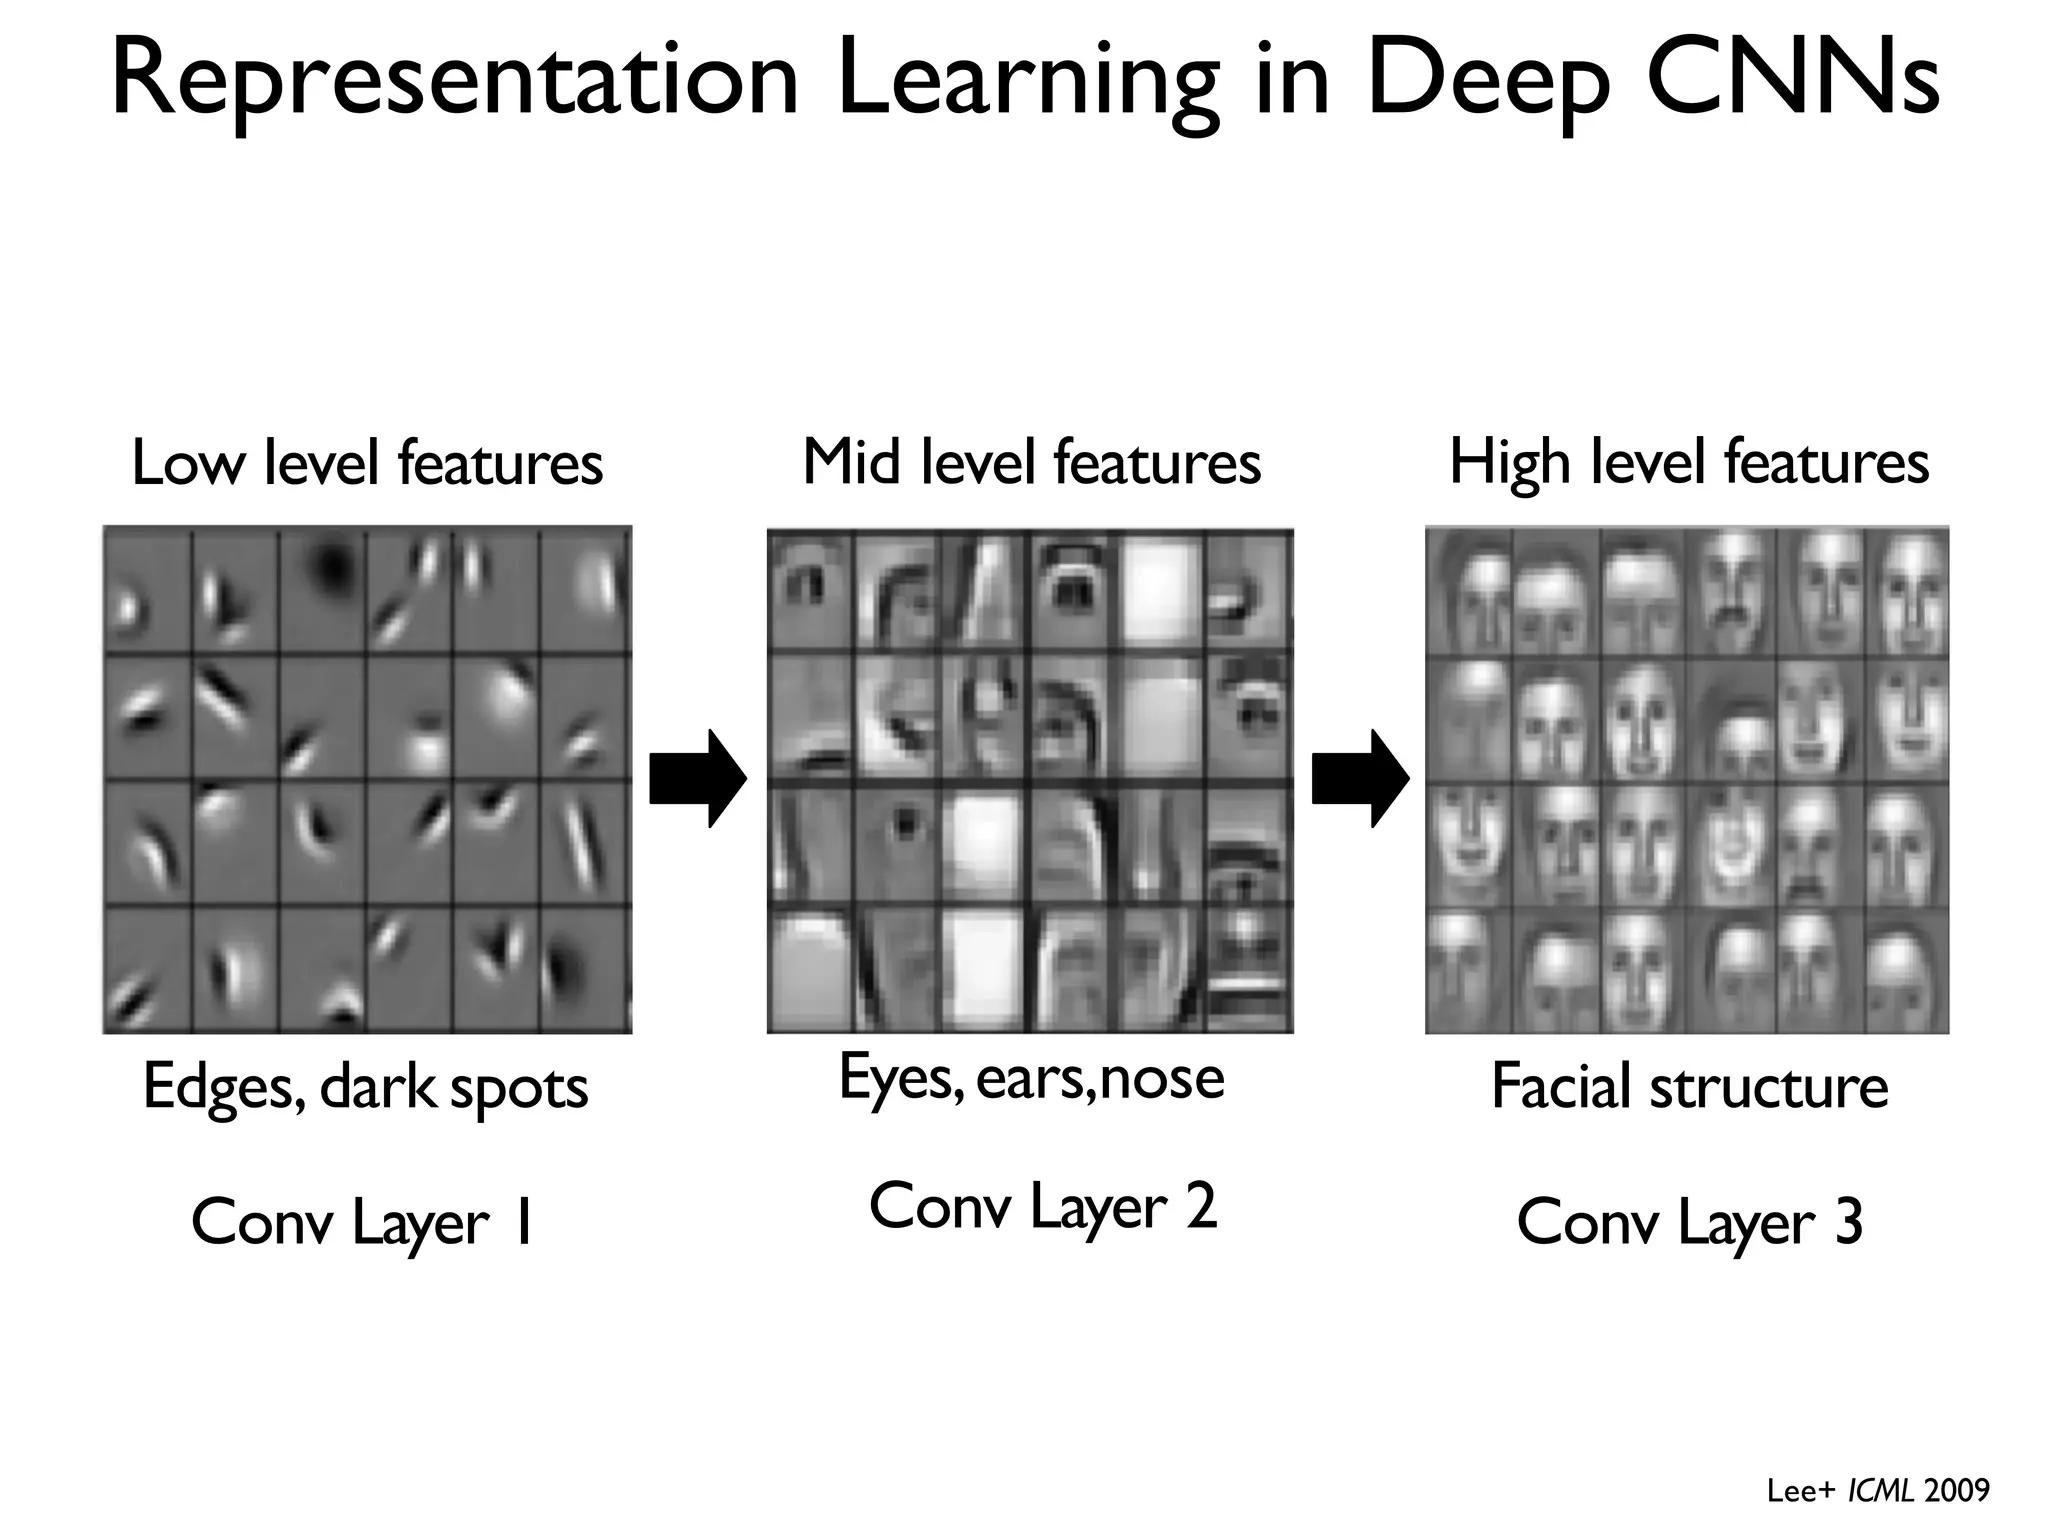

This is where deep learning becomes important.

A neural network processes the aligned face and learns meaningful facial characteristics.

For example, it can learn visual patterns related to:

- Eye shape and surrounding regions.
- Nose structure.
- Facial contours.
- Mouth and cheek regions.
- Relationships between facial features.

These are learned representations, not necessarily manually calculated measurements.

Think about the CNN architectures you previously studied:

```text
Face Image
    ↓
Convolution Layers
    ↓
Feature Maps
    ↓
Learned Facial Features
```

The network learns useful representations from training examples.

### Stage 5 — Embedding Generation

<text style="font-weight:bold;">Very Important</text>

A **face embedding** is a numerical vector that represents the facial characteristics learned by the neural network.

Instead of comparing two complete images pixel by pixel, the recognition system compares their embeddings.

For example, a model might produce a 512-dimensional embedding:

```python
face_embedding = [
    0.12,
    -0.34,
    0.56,
    0.21,
    ...
]
```

Mathematically:

$$
f(I)=\mathbf{e}\in\mathbb{R}^{512}
$$

Where:

- \(I\) = Input face image.
- \(f\) = Trained neural network.
- \(\mathbf{e}\) = Face embedding.
- \(512\) = Example embedding dimension, not a universal requirement.

**Important intuition:**

Imagine two photographs of the same person:

- Photograph A: Taken in the morning.
- Photograph B: Taken in the evening.

Their pixel values may differ considerably, but a well-trained recognition model should generate embeddings that are relatively close in the embedding space.

Photographs of different people should generally produce embeddings that are farther apart.

### Stage 6 — Similarity Measurement

Now we have two embeddings.

Our objective is to determine how similar they are.

Let's consider:

$$
A=[1,2,3]
$$

$$
B=[1,2,3]
$$

These vectors are identical, so their similarity is maximum.

Now consider:

$$
C=[8,4,1]
$$

This vector is different from A.

There are several mathematical methods for comparing embeddings.

#### A. Cosine Similarity

Cosine similarity measures the angle between two vectors.

$$
\text{Cosine Similarity}(A,B)=
\frac{A\cdot B}{\|A\|\|B\|}
$$

Where:

- \(A\cdot B\) = Dot product.
- \(\|A\|\) = Magnitude of vector A.
- \(\|B\|\) = Magnitude of vector B.

For normalized, nonzero vectors, cosine similarity ranges from -1 to +1.

A higher value generally indicates greater similarity.

#### B. Euclidean Distance

Euclidean distance measures the straight-line distance between two embedding vectors.

$$
d(A,B)=\sqrt{\sum_{i=1}^{n}(A_i-B_i)^2}
$$

A smaller distance indicates greater similarity.

#### Cosine Similarity vs Euclidean Distance

| Method | Interpretation |
|---|---|
| Cosine similarity | Higher generally means more similar |
| Euclidean distance | Lower generally means more similar |

The correct metric depends on how the recognition model was trained and how its embeddings are intended to be compared.

### Stage 7 — Decision

The final stage determines whether two faces match.

A threshold is used to make the decision.

**For cosine similarity:**

```text
Similarity score = 0.92
Threshold        = 0.80

0.92 >= 0.80

Decision: MATCH
```

**For Euclidean distance:**

```text
Distance  = 0.35
Threshold = 0.60

0.35 <= 0.60

Decision: MATCH
```

These are illustrative values, not universal thresholds.

The threshold must be selected and validated for the particular model, dataset and application.

---

## 2. Putting Everything Together

Let's visualize the complete process.

```text
Input Face Image
       |
       v
Face Detection + Alignment
       |
       | Locate and geometrically
       | standardize the face
       v
Face Representation
       |
       | Deep neural network
       | learns facial features
       v
Embedding
       |
       | [0.12, -0.34, 0.56, ...]
       |
       | Numerical representation
       v
Similarity Measurement
       |
       | Compare two face embeddings
       v
Decision
       |
       ├── MATCH
       |   Meets the matching threshold
       |
       └── NO MATCH
           Does not meet the threshold
```

---

## 3. Two Important Types of Face Recognition

You should understand this distinction.

### A. Face Verification (1:1)

**Question:** Is this person the same person as the registered user?

Example: Unlocking a smartphone using your registered face.

```text
Captured Face
      ↓
Compare with Registered Face
      ↓
MATCH / NO MATCH
```

### B. Face Identification (1:N)

**Question:** Who is this person among the registered identities?

Example: Searching a face against a database of registered identities.

```text
Captured Face
      ↓
Generate Embedding
      ↓
Compare Against Database
      ↓
Find Closest Candidate(s)
```

### Verification vs Identification

| Feature | Verification | Identification |
|---|---|---|
| Comparison | 1:1 | 1:N |
| Purpose | Confirm identity | Find identity |
| Example | Phone unlock | Database search |

Identification may also return no match if no candidate satisfies the required threshold.

---

## 4. Industry-Level Implementation Concept

A pretrained face recognition model can perform embedding extraction.

For example, architectures such as **FaceNet** and **ArcFace** are widely studied in this area.

### FaceNet

Learns an embedding space using **triplet loss**.

### ArcFace

Uses an **additive angular margin loss** to improve discriminative embeddings.

You don't need to train a recognition network from scratch at this stage.

We can later use a pretrained model with PyTorch and CUDA to extract embeddings and compare faces.

**Important deployment consideration:**

A face match is not proof of a person's identity by itself. Real authentication systems also need:

- Presentation-attack detection (liveness checks).
- Secure data handling.
- Carefully evaluated error rates.

---

## 5. What You Should Remember

1. Face detection locates the face.
2. Face alignment standardizes its geometry.
3. Face representation is learned by a deep neural network.
4. Embedding converts learned facial information into a numerical vector.
5. Similarity measures how close two embeddings are.
6. A threshold determines the matching decision.
7. Verification is 1:1; identification is 1:N.

---